In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

Represent a dem in as a vector of elevations $d$.

A simple 1D case could looke like $d = (4, 2, 4, 1, 4)$, where each element represents the elevation at a specific point along a line and we denote the elements using an index notation,  $d_1, d_2, d_3, d_4, d_5$.

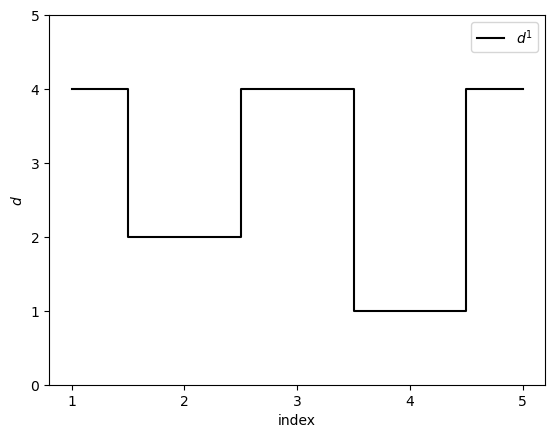

In [63]:
d = np.array([4, 2, 4, 1, 4])
plt.step(np.arange(len(d))+1.0, d, where='mid',label = '$d^1$', color ='black')
plt.legend()
plt.xlabel('index')
plt.ylabel('$d$')
plt.ylim(0,5)

plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))


We also represent the water input as a vector of the same length as $d$, denoted as $w = (w_1, w_2, w_3, w_4, w_5)$, where each element represents the amount of water input at the corresponding point along the line.

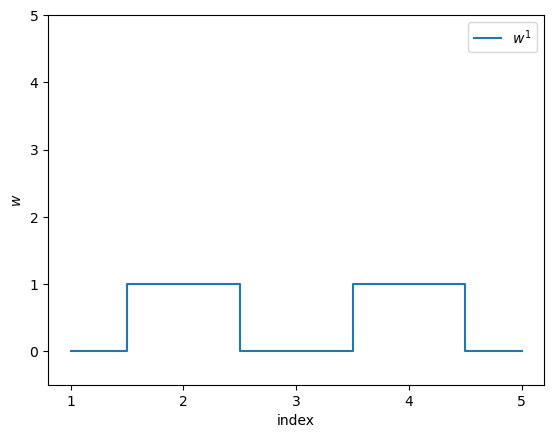

In [36]:
w = np.array([0, 1, 0, 1, 0])
plt.step(np.arange(len(w))+1.0, w, where='mid',label = '$w^1$')
plt.legend()
plt.xlabel('index')
plt.ylabel('$w$')
plt.ylim(-0.5,5)
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))

To represent the vector in a 2-d space, we need to reduce them somehow. In this very simply case we can just take the second and fourth indexes and use them to plot the locaiton of the vector in a 2-d space because the other three vectors are uniform and (by construction) will not change. We will remember that in reality the space is five dimensional, we are just plotting a projection of that space onto 2 dimensions and we chose which 2 dimensions to focus on based on what we think is going to change in an interesting way. 

In [46]:
def to_2d(X):
    # Reduce the vectors to 2D by selecting the second and fourth elements
    return np.array([X[1], X[3]])

In [49]:
def add_arrow(end, start=(0, 0), ax=None, color='k', lw=2, label=None, **kwargs):
    """Draw an arrow from start to end on ax (defaults to current axes)."""
    ax = ax or plt.gca()
    ax.annotate('', xy=end, xytext=start,
                arrowprops=dict(arrowstyle='->', color=color, lw=lw, **kwargs))
    if label is not None:
        ax.text(*end, f' {label}', color=color, va='bottom')
    # annotate doesn't trigger autoscaling, so register the points
    ax.update_datalim([start, end])
    ax.autoscale_view()

/var/folders/kl/3mt9f4qs1559xwy3mr60s7980000gp/T/ipykernel_35043/1869375665.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


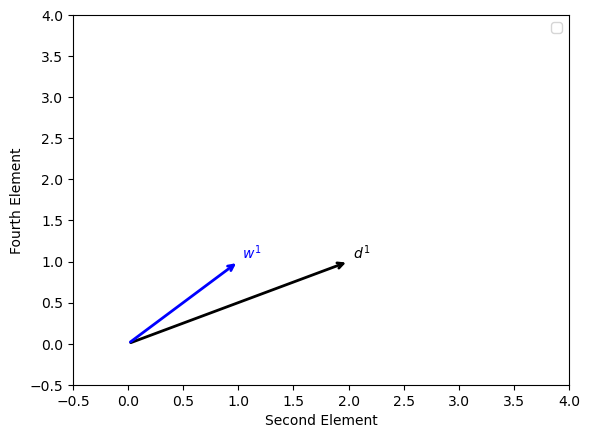

In [55]:
fig, ax = plt.subplots()
add_arrow(to_2d(d), color='black', label='$d^1$')
add_arrow(to_2d(w), color='b', label='$w^1$')

plt.xlabel('Second Element')
plt.ylabel('Fourth Element')
plt.ylim(-0.5,4)
plt.xlim(-0.5,4)

plt.legend()

Now consider what would happen when we apply the fill-spill-merge function, $F$, to $d^1$ and $w^1$. Symbolically, this operation is represented as $F(d^1, w^1)$ (we are thinking of this as routing the water and adding it to the dem, then returning the dem + routed water height as an output). 

Graphically from the line plots above we can see $F(d^1, w^1)$ neither derpession will fill as a result of adding this amount of water, so the result of the fill-spill-merge function will be the same as $d^1 + w^1$.

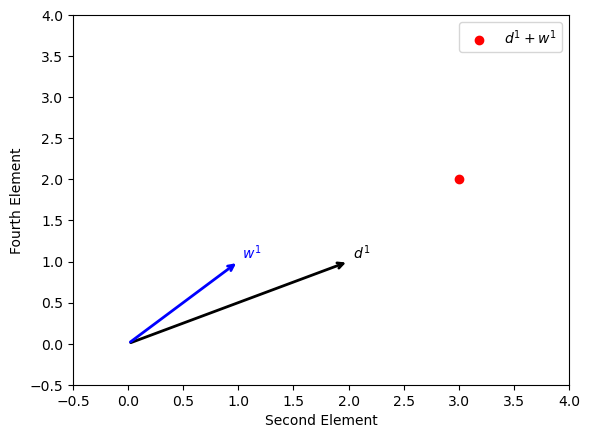

In [72]:
fig, ax = plt.subplots()
add_arrow(to_2d(d), color='black', label='$d^1$')
add_arrow(to_2d(w), color='b', label='$w^1$')
ax.scatter(to_2d(d+w)[0], to_2d(d+w)[1], color='r', label='$d^1 + w^1$')

ax.set_xlabel('Second Element')
ax.set_ylabel('Fourth Element')
ax.set_ylim(-0.5,4)
ax.set_xlim(-0.5,4)

ax.legend()

In the spatial representation this is simply:

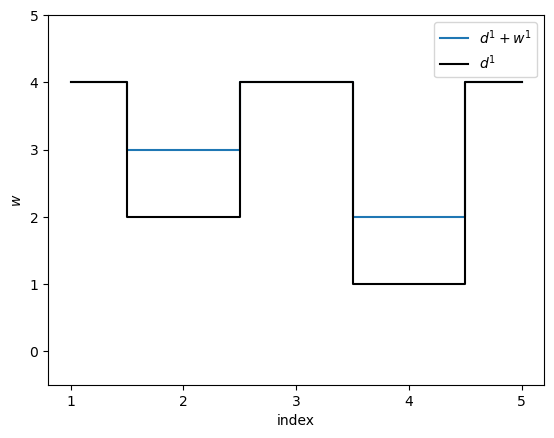

In [64]:
plt.step(np.arange(len(w))+1.0, w+d, where='mid',label = '$d^1 + w^1$')
plt.step(np.arange(len(w))+1.0, d, where='mid',label = '$d^1$', color = 'black')
plt.legend()
plt.xlabel('index')
plt.ylabel('$w$')
plt.ylim(-0.5,5)
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))

Neither of the basin are full, so $d^2 = F(d^1, w^1) = d^1 + w^1$.

You can mark on the phase space where the basins would fill:

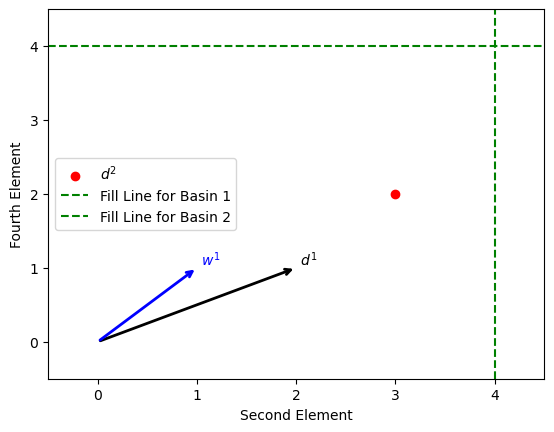

In [84]:
fig, ax = plt.subplots()
add_arrow(to_2d(d), color='black', label='$d^1$')
add_arrow(to_2d(w), color='b', label='$w^1$')
ax.scatter(to_2d(d+w)[0], to_2d(d+w)[1], color='r', label='$d^2$')

ax.axhline(y=4, color='g', linestyle='--', label='Fill Line for Basin 1')
ax.axvline(x=4, color='g', linestyle='--', label='Fill Line for Basin 2')

ax.set_xlabel('Second Element')
ax.set_ylabel('Fourth Element')
ax.set_ylim(-0.5, 4.5)
ax.set_xlim(-0.5, 4.5)

ax.legend()